# Signal Lab: AI trading project

A presentation-ready walkthrough of the complete, auditable trading workflow. The notebook compares candidate strategies, explains the selected rule, shows saved results, and checks the competition contract.

**Honest result:** the selected 20/100-day trend rule did not beat buy-and-hold on the saved 2023 development check.

## Executive summary

- Input: daily OHLCV history for 34 stocks from 2015–2024.
- Candidates: smooth trend, Ridge, Extra Trees, starter trend, and defensive trend.
- Selection: chronological 2019–2022 validation; score = mean Sharpe − 0.25 × cross-year Sharpe standard deviation.
- Winner: `starter_trend`, long when the 20-day average exceeds the 100-day average; otherwise cash.
- 2023 practice: selected model returned 0.88% with Sharpe 0.14; buy-and-hold returned 16.07% with Sharpe 1.19.

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings('ignore')
ROOT = Path.cwd()
if not (ROOT / 'competition-submission').exists(): ROOT = Path('..').resolve()
SUBMISSION = ROOT / 'competition-submission'
sys.path.insert(0, str(SUBMISSION))
import sdsu_harness as harness
from strategy import make_features, fit_strategy
print('Project root:', ROOT)

Project root: /Users/justin/Documents/GitHub/ai-stock-trading-comp


## 1. Data and contract

The harness validates each OHLCV frame, gives the strategy history through the prior close, executes at the next open, marks at the following open, and applies a 0.1% fee. A prediction must be a deterministic Python float in [-1, 1].

In [2]:
source = pd.read_csv(SUBMISSION / 'data' / 'stock_prices_2015_2024.csv', parse_dates=['Date'])
DATA = {t: harness.clean_frame(f.drop(columns=['Ticker'])) for t, f in source.groupby('Ticker')}
audit = pd.DataFrame({'Rows':[len(source)], 'Tickers':[source.Ticker.nunique()], 'Start':[source.Date.min().date()], 'End':[source.Date.max().date()], 'Null cells':[int(source.isna().sum().sum())], 'Duplicate ticker-date keys':[int(source.duplicated(['Ticker','Date']).sum())]})
display(audit)
display(source.head())

,Rows,Tickers,Start,End,Null cells,Duplicate ticker-date keys
0,85544,34,2015-01-02,2024-12-31,0,0


,Date,Ticker,Open,High,Low,Close,Volume
0,2015-01-02,AAL,51.430489,51.733690,50.284011,51.079914,10748600
1,2015-01-02,AAPL,24.627205,24.638260,23.734002,24.171761,212818400
2,2015-01-02,AMZN,15.629000,15.737500,15.348000,15.426000,55664000
3,2015-01-02,BA,114.636798,115.310248,112.905035,113.657211,4294200
4,2015-01-02,C,39.884954,40.127080,39.466735,39.811581,11137800


## 2. Causal features

The learned candidates use lagged returns, 20- and 100-day trends, trailing volatility, daily range, relative volume, opening gap, intraday return, and close location. No ticker identifier, price level, date, or future value is used.

In [3]:
features = make_features(DATA['AAPL'])
display(pd.DataFrame({'Feature':features.columns, 'Final row available':[bool(features[c].iloc[-1:].notna().all()) for c in features.columns]}))
display(features.tail(3))

,Feature,Final row available
0,return_1,True
1,return_5,True
2,return_20,True
3,return_60,True
4,return_120,True
5,trend_20,True
6,trend_100,True
7,volatility_20,True
8,volatility_60,True
9,daily_range,True


,return_1,return_5,return_20,return_60,return_120,trend_20,trend_100,volatility_20,volatility_60,daily_range,relative_volume_20,opening_gap,intraday_return,close_location
Date,,,,,,,,,,,,,,
2024-12-27,-0.013242,0.023220,0.087941,0.128279,0.120200,0.028430,0.108369,0.009615,0.010593,0.022067,-0.090463,-0.004594,-0.008688,0.448580
2024-12-30,-0.013263,-0.008998,0.062655,0.118791,0.084942,0.011762,0.091639,0.010262,0.010741,0.010904,-0.242196,-0.013146,-0.000119,0.527272
2024-12-31,-0.007058,-0.019000,0.045202,0.105359,0.102894,0.002444,0.082174,0.010385,0.010795,0.015374,-0.150751,0.000952,-0.008002,0.257144


## 3. Chronological model selection

The saved tables below are produced by `workflow.py`. Set `RUN_FULL_WORKFLOW = True` to recompute the complete walk-forward selection from the official CSV. The 2023 and 2024 checks are documented as development diagnostics, not secret competition results.

In [4]:
RUN_FULL_WORKFLOW = False
if RUN_FULL_WORKFLOW:
    import workflow
    workflow.run_workflow(DATA, SUBMISSION)
selection = pd.read_csv(SUBMISSION / 'model_selection.csv')
validation = pd.read_csv(SUBMISSION / 'validation_results.csv')
display(selection.style.format({'mean_sharpe':'{:.3f}','std_sharpe':'{:.3f}','selection_score':'{:.3f}'}))
display(validation.pivot(index='year', columns='kind', values='Sharpe').round(3))
selected_kind = selection.iloc[0]['kind']
print('Selected model:', selected_kind)

,kind,mean_sharpe,std_sharpe,selection_score
0,starter_trend,1.188,0.610,1.036
1,defensive_trend,1.084,0.916,0.855
2,trend,0.719,0.837,0.510
3,extra_trees,0.689,0.930,0.456
4,ridge,0.577,0.880,0.357


kind,defensive_trend,extra_trees,ridge,starter_trend,trend
year,,,,,
2019,1.651,1.541,1.250,1.256,1.395
2020,1.781,0.898,0.801,1.964,1.082
2021,1.125,0.951,0.970,1.042,0.897
2022,-0.222,-0.635,-0.713,0.490,-0.498


Selected model: starter_trend


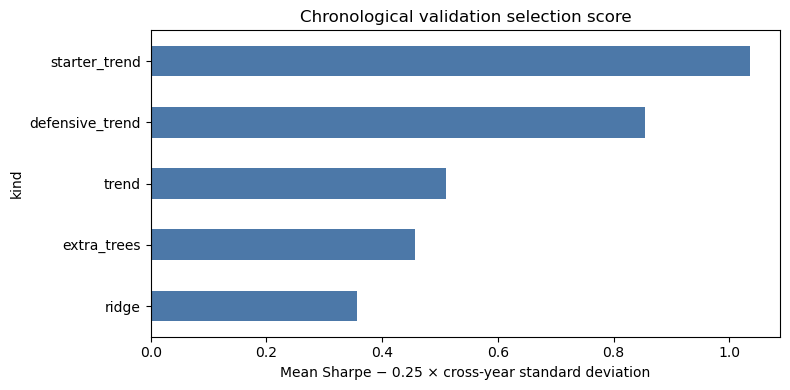

In [5]:
ax = selection.sort_values('selection_score').plot.barh(x='kind', y='selection_score', legend=False, figsize=(8,4), color='#4c78a8')
ax.set_xlabel('Mean Sharpe − 0.25 × cross-year standard deviation')
ax.set_title('Chronological validation selection score')
plt.tight_layout(); plt.show()

## 4. The selected rule

The winning rule is intentionally simple: 20-day average above 100-day average means fully long (`1.0`); otherwise cash (`0.0`). It has no fitted coefficients, no mutable state, and no fitting inside `predict`.

In [6]:
model = fit_strategy({t:f.loc[:'2022-12-31'].copy() for t,f in DATA.items()}, kind='starter_trend')
description = model.describe()
display(pd.DataFrame({'Property':['Kind','Minimum history','Learned parameters','Training rows','Timing'], 'Value':[description['kind'],description['minimum_history'],description['learned_parameters'],description['training_rows'],description['timing']]}))
print('Example AAPL position:', model.predict(DATA['AAPL'].loc[:'2022-12-31'].tail(120)))

,Property,Value
0,Kind,starter_trend
1,Minimum history,100
2,Learned parameters,False
3,Training rows,64328
4,Timing,history through close t; position executed at ...


Example AAPL position: 0.0


## 5. Practice result versus buy-and-hold

This is the saved 2023 practice check on AAPL, JPM, XOM, and JNJ. It was not used in the numerical selection score, although it was reused as a development diagnostic.

,Sharpe,Total return,Max drawdown,Final equity,Intervals,Fees paid,Trades
Selected model,0.139,0.88%,-7.50%,"$10,087.56",249.000000,$53.94,22
Buy and hold,1.190,16.07%,-10.66%,"$11,606.91",249.000000,$21.61,8


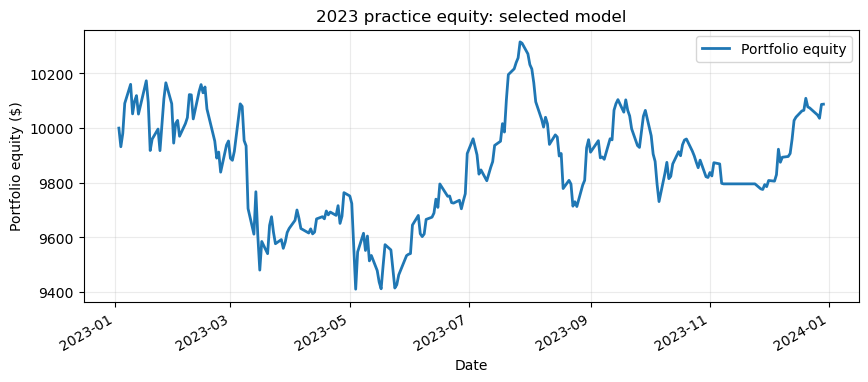

In [7]:
practice = pd.read_csv(SUBMISSION / 'practice_metrics.csv', index_col=0)
display(practice.style.format({'Sharpe':'{:.3f}','Total return':'{:.2%}','Max drawdown':'{:.2%}','Final equity':'${:,.2f}','Fees paid':'${:,.2f}','Trades':'{:.0f}'}))
equity = pd.read_csv(SUBMISSION / 'practice_equity.csv', index_col=0, parse_dates=True)
equity.plot(figsize=(10,4), linewidth=2, title='2023 practice equity: selected model'); plt.ylabel('Portfolio equity ($)'); plt.grid(alpha=.25); plt.show()

## 6. Contract checks and deliverables

The smoke check verifies deterministic output, valid position range, input immutability, and acceptable speed. The repository also contains unit tests for causal features, rules, the official harness, and isolated serialization.

In [8]:
display(pd.DataFrame([harness.smoke_check_predict(model.predict)]))
print('Serialized submission exists:', (SUBMISSION / 'Signal_Lab_submission.pkl').exists())
print('Full tests: cd competition-submission && python -m unittest -v test_strategy.py')

,dummy_position,seconds_per_call,passed
0,0.0,0.0002,True


Serialized submission exists: True
Full tests: cd competition-submission && python -m unittest -v test_strategy.py


## What the project completes

1. Validates official source data.
2. Builds causal features and candidate strategies.
3. Performs walk-forward chronological model selection.
4. Freezes the selected strategy before the practice year.
5. Backtests through the official harness with timing and fees.
6. Exports metrics, equity, trades, selection evidence, a serialized submission, and an audit trail.

See `PROJECT_PRESENTATION_SCRIPT.md` for the ready-to-read talk track.